# 06 · SME pilot evaluation analysis plan (Phase 4) — on a SYNTHETIC dataset
**Supports:** RQ2, RQ4, RQ5; concept note §8 metrics. The dataset is generated here so the full analysis can be pre-registered and tested before any pilot data exists. Replace with `experiments/data-templates/pilot_metrics.csv`.
Principles from the concept note: effect sizes with CIs, case-wise reporting, no causal claim from before/after alone.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from crasme import plotting; plotting.use()
pd.set_option('display.precision', 3); pd.set_option('display.width', 140)
from crasme import stats as s

In [2]:
rng = np.random.default_rng(2026)
n = 8
smes = pd.DataFrame({'sme': [f'SME{i+1}' for i in range(n)],
                     'product_type': rng.choice(['software', 'iot', 'embedded'], n),
                     'ci_maturity': rng.integers(1, 5, n)})
smes['trace_before'] = rng.uniform(0.1, 0.45, n)
smes['trace_after'] = np.clip(smes.trace_before + rng.normal(0.3, 0.12, n), 0, 1)
smes['remed_days_before'] = rng.lognormal(np.log(30), 0.5, n)
smes['remed_days_after'] = smes.remed_days_before * rng.lognormal(np.log(0.75), 0.35, n)
smes['hours_per_release_before'] = rng.uniform(10, 40, n)
smes['hours_per_release_after'] = smes.hours_per_release_before * rng.lognormal(np.log(0.85), 0.3, n)
smes.round(2)

,sme,product_type,ci_maturity,trace_before,trace_after,remed_days_before,remed_days_after,hours_per_release_before,hours_per_release_after
0,SME1,embedded,3,0.33,0.58,41.35,41.53,17.85,32.69
1,SME2,software,2,0.20,0.57,74.70,83.43,31.03,67.87
2,SME3,software,4,0.44,0.72,21.00,11.55,16.84,23.26
3,SME4,iot,4,0.42,0.56,58.87,56.10,24.79,27.01
4,SME5,iot,3,0.32,0.57,16.22,10.14,27.40,19.09
5,SME6,iot,4,0.36,0.74,32.74,20.92,15.67,17.95
6,SME7,software,3,0.28,0.55,16.72,14.97,31.94,23.77
7,SME8,iot,1,0.39,0.67,58.96,60.11,26.45,22.34


In [3]:
out = {}
for m, better in [('trace', 'higher'), ('remed_days', 'lower'), ('hours_per_release', 'lower')]:
    r = s.paired_summary(smes[f'{m}_before'], smes[f'{m}_after'], better=better)
    out[m] = {**r, 'better_if': better}
pd.DataFrame(out).T[['n', 'median_diff', 'median_diff_ci95', 'hedges_gz', 'wilcoxon_p', 'improved_cases', 'worse_cases', 'better_if']]

,n,median_diff,median_diff_ci95,hedges_gz,wilcoxon_p,improved_cases,worse_cases,better_if
trace,8,0.277,"(0.24272655364401519, 0.3315683287291604)",3.239,0.008,8,0,higher
remed_days,8,-2.256,"(-9.448239653143636, 1.1412002508453796)",-0.374,0.25,5,3,lower
hours_per_release,8,2.248,"(-8.166714932466036, 14.845426322562613)",0.313,0.641,3,5,lower


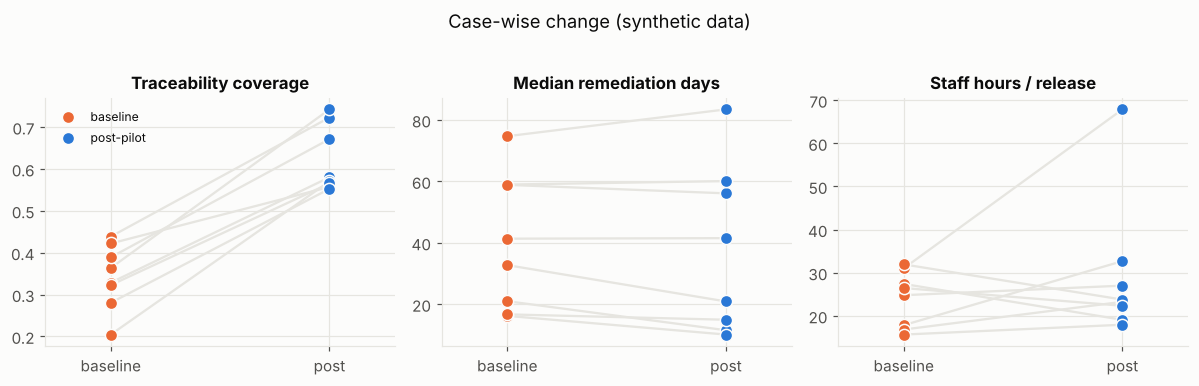

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, (m, lbl) in zip(axes, [('trace', 'Traceability coverage'), ('remed_days', 'Median remediation days'), ('hours_per_release', 'Staff hours / release')]):
    for i, row in smes.iterrows():
        ax.plot([0, 1], [row[f'{m}_before'], row[f'{m}_after']], color=plotting.GRID, lw=1.5)
    ax.plot(np.zeros(n), smes[f'{m}_before'], 'o', color=plotting.SERIES[1], label='baseline', markeredgecolor=plotting.SURFACE)
    ax.plot(np.ones(n), smes[f'{m}_after'], 'o', color=plotting.SERIES[0], label='post-pilot', markeredgecolor=plotting.SURFACE)
    ax.set_xticks([0, 1], ['baseline', 'post']); ax.set_title(lbl); ax.set_xlim(-0.3, 1.3)
axes[0].legend(fontsize=8); plt.suptitle('Case-wise change (synthetic data)', y=1.02); plt.tight_layout(); plt.show()

## Stratification (RQ5) — descriptive only with n ≈ 8

In [5]:
smes['trace_gain'] = smes.trace_after - smes.trace_before
smes.groupby('product_type').agg(n=('sme', 'count'), median_gain=('trace_gain', 'median'), min_gain=('trace_gain', 'min'), max_gain=('trace_gain', 'max'))

,n,median_gain,min_gain,max_gain
product_type,,,,
embedded,1,0.252,0.252,0.252
iot,4,0.262,0.135,0.379
software,3,0.284,0.272,0.366


## Power for a paired Wilcoxon test at the planned sample sizes
With 6–10 SMEs only large effects are detectable; this justifies the concept note's emphasis on effect sizes and qualitative evidence.

In [6]:
pw = pd.DataFrame([{'n_sme': k, 'dz': dz, 'power': s.power_paired_wilcoxon(k, dz, n_sim=1500)} for k in (6, 8, 10) for dz in (0.5, 0.8, 1.2)])
pw.pivot(index='n_sme', columns='dz', values='power')

dz,0.5,0.8,1.2
n_sme,,,
6,0.112,0.252,0.494
8,0.184,0.430,0.773
10,0.278,0.603,0.905


## Staggered roll-out (if recruitment allows)
Three waves start the intervention in different months; a two-way fixed-effects estimate is shown with its known caveat.

In [7]:
rows = []
start = dict(zip(smes.sme, rng.choice([2, 3, 4], n)))
for sme, st in start.items():
    base = rng.uniform(0.15, 0.4)
    for p in range(1, 6):
        tr = int(p >= st)
        rows.append({'sme': sme, 'period': p, 'treated': tr, 'trace': base + 0.02*p + 0.25*tr + rng.normal(0, 0.04)})
panel = pd.DataFrame(rows); s.staggered_did(panel, 'trace')

{'effect': 0.23401842877474516,
 'se': 0.02585667783104591,
 'dof': 27,
 'note': 'TWFE can be biased with heterogeneous effects in staggered designs; report case-wise too.'}